# Spotify Analysis with Cassandra (Simple Version)

**What this notebook does:**
1. Read songs from Cassandra (not CSV).
2. Calculate and save a custom popularity score in the same table.
3. Find the **top 3 artists by total streams**.
4. Show each top artist’s **top 5 songs and their total streams**.
5. Train a simple ML model and recommend similar songs.

**Before running:** Start Cassandra and run your ingestion notebook first. This version uses `spotify.spotify_youtube_full`, which contains artist, track, stream and audio-feature columns.

## 1. Install required libraries

In [1]:
%pip install pandas cassandra-driver scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries and set table name

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from cassandra.cluster import Cluster
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import pickle

KEYSPACE = "spotify"
TABLE = "spotify_youtube_full"
AUDIO = ["danceability", "energy", "key", "loudness", "speechiness",
         "acousticness", "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
ENGAGEMENT = ["stream", "views", "likes", "comments"]

## 3. Connect and read data from Cassandra

Explanation — Connect to Cassandra and load the dataset
This cell connects to Cassandra on the local machine at 127.0.0.1:9042, selects the configured keyspace, and reads all rows from the table into a pandas DataFrame called df.

df.shape reports the number of rows and columns, and df.head() previews the first few records. If the table is empty, the cell stops with an error. Cassandra must be running and the data must already have been ingested.

In [3]:
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect(KEYSPACE)
rows = session.execute(f"SELECT * FROM {TABLE}")
df = pd.DataFrame([row._asdict() for row in rows])
print("Rows and columns:", df.shape)
display(df.head())
if df.empty:
    raise ValueError("No data found. Run the ingestion notebook first.")

Rows and columns: (19170, 29)


,row_id,acousticness,album,album_type,artist,channel,comments,danceability,description,duration_ms,...,speechiness,stream,tempo,title,track,uri,url_spotify,url_youtube,valence,views
0,4317,0.796,Tuesday Night Music Club,album,Sheryl Crow,MAINSTREAM TOP MUSIC,102.0,0.580,Strong Enough · Sheryl Crow Tuesday Night Musi...,189827.0,...,0.0317,51767995.0,154.595,SHERYL CROW - STRONG ENOUGH (OFFICIAL MUSIC V...,Strong Enough,spotify:track:25IRjWUZ60n7KXxcB4DiX9,https://open.spotify.com/artist/4TKTii6gnOnUXQ...,https://www.youtube.com/watch?v=7CCWMMEN1Vc,0.583,97038.0
1,3372,0.776,At Last!,album,Etta James,Classic Mood Experience,185.0,0.486,Classic Mood Experience The best masterpieces ...,178467.0,...,0.0309,17660226.0,64.033,Etta James - Trust In Me,Trust In Me,spotify:track:5Zu9mG353GB3p26t7M5AmR,https://open.spotify.com/artist/0iOVhN3tnSvgDb...,https://www.youtube.com/watch?v=rwWJgHEcMrs,0.500,985595.0
2,14340,0.664,Mon Laferte (Vol. 1),album,Mon Laferte,MonLaferteVEVO,14805.0,0.393,Producido y Dirigido por Carolina Dagach\n\nSt...,241880.0,...,0.0269,129999337.0,175.548,Mon Laferte - Amor Completo,Amor Completo,spotify:track:00kIWJu9IHiQ6i0qJAU0Z9,https://open.spotify.com/artist/4boI7bJtmB1L3b...,https://www.youtube.com/watch?v=PQlG1gznMBE,0.346,170138206.0
3,18417,0.301,Nie mehr gehen,single,Apache 207,Apache 207,3092.0,0.704,Vorverkaufsstart - Dienstag 25.10 / 16:00 auf ...,195925.0,...,0.0425,9903711.0,139.924,DANKESCHÖN (Nie mehr gehen),Nie mehr gehen,spotify:track:3iBU3w9MbrqFdB9mOa2JeK,https://open.spotify.com/artist/1qQLhymHXFPtP5...,https://www.youtube.com/watch?v=UaOdBXw9SY0,0.240,2293294.0
4,1584,0.733,Star Wars: The Phantom Menace (Original Motion...,album,London Symphony Orchestra,FilmTrailersChannel,285.0,0.471,Duel Of Fates Music Video\n\nConducted And Wri...,254347.0,...,0.0410,91702045.0,79.986,Star Wars The Phantom Menace Music Video - [Du...,Duel of the Fates,spotify:track:1ghlpxVfPbFH2jenrv9vVw,https://open.spotify.com/artist/5yxyJsFanEAuwS...,https://www.youtube.com/watch?v=nIgZS5tieeE,0.282,259284.0


## 4. Convert numbers to numeric format

Explanation — Clean and validate numeric columns
This cell keeps only the audio and engagement columns that actually exist in the table, then converts their values to numeric types. Values that cannot be converted become missing values (NaN) instead of causing conversion errors.

It also checks that stream, artist, and track are available because later cells need them for artist rankings and song-level analysis.

In [4]:
audio_cols = [c for c in AUDIO if c in df.columns]
engagement_cols = [c for c in ENGAGEMENT if c in df.columns]
for col in audio_cols + engagement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if "stream" not in df.columns:
    raise ValueError("The table needs a 'stream' column for stream totals.")
if "artist" not in df.columns or "track" not in df.columns:
    raise ValueError("The table needs 'artist' and 'track' columns.")

## 5. Calculate popularity score (0–100)

Explanation — Calculate a custom popularity score
This cell creates a custom score from 0 to 100 using the available engagement columns. np.log1p() reduces the effect of very large engagement values, and each column is normalized to a 0–1 range before the available normalized columns are averaged and multiplied by 100.

This is a project-defined score, not Spotify's official popularity score. The formula gives each available engagement column equal weight after normalization. If there are no engagement columns, the cell raises an error.

In [5]:
# This is our custom score, not Spotify's official popularity score.
if not engagement_cols:
    raise ValueError("No engagement columns found.")

parts = []
for col in engagement_cols:
    values = np.log1p(df[col].clip(lower=0))
    spread = values.max() - values.min()
    parts.append((values - values.min()) / spread if spread > 0 else values * 0)

df["popularity_score"] = (pd.concat(parts, axis=1).mean(axis=1) * 100).round(2)
display(df[["artist", "track", "popularity_score"]].head())

,artist,track,popularity_score
0,Sheryl Crow,Strong Enough,45.08
1,Etta James,Trust In Me,48.99
2,Mon Laferte,Amor Completo,72.24
3,Apache 207,Nie mehr gehen,56.02
4,London Symphony Orchestra,Duel of the Fates,50.14


## 6. Save score to the same Cassandra table

Explanation — Save popularity scores in Cassandra
This cell attempts to add a popularity_score column to the Cassandra table. If the column already exists, the expected duplicate-column error is ignored; other errors are raised.

It then updates each row's score using row_id as the row identifier. Make sure row_id is the table's primary key and that its type matches the conversion used here. This operation writes the calculated scores back to Cassandra.

In [6]:
# Add the column if it is not already present.
try:
    session.execute(f"ALTER TABLE {TABLE} ADD popularity_score double")
except Exception as e:
    if "already exists" not in str(e).lower() and "conflicts with an existing column" not in str(e).lower():
        raise

# row_id must be the table's primary key.
update = session.prepare(f"UPDATE {TABLE} SET popularity_score = ? WHERE row_id = ?")
for row in df[["row_id", "popularity_score"]].itertuples(index=False):
    update_score, row_id = row.popularity_score, row.row_id
    session.execute(update, (float(update_score), int(row_id)))
print("Popularity scores saved to the same Cassandra table.")

Popularity scores saved to the same Cassandra table.


## 7. Most popular artists by total streams

,artist,total_streams
1470,Post Malone,1.525126e+10
516,Ed Sheeran,1.439488e+10
497,Dua Lipa,1.340808e+10


Most popular artist: Post Malone
Total streams: 15,251,263,853


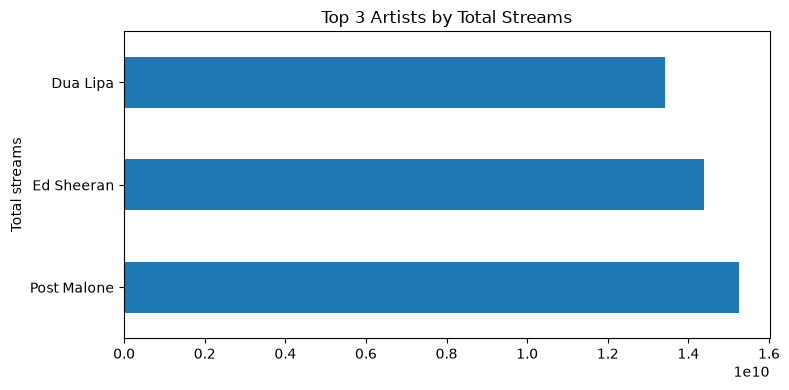

In [18]:
# Sum streams for each artist, then show the top 3.
artist_streams = (
    df.dropna(subset=["artist", "stream"])
      .groupby("artist", as_index=False)["stream"].sum()
      .rename(columns={"stream": "total_streams"})
      .sort_values("total_streams", ascending=False)
)
top3_artists = artist_streams.head(3)
display(top3_artists)

print("Most popular artist:", top3_artists.iloc[0]["artist"])
print("Total streams:", f"{top3_artists.iloc[0]['total_streams']:,.0f}")
top3_artists.plot(x="artist", y="total_streams", kind="barh", legend=False, title="Top 3 Artists by Total Streams", figsize=(8,4))
plt.ylabel("Total streams")
plt.tight_layout()
plt.show()

## 8. Top 5 songs for each of the top 3 artists

In [8]:
# If a track appears more than once for an artist, sum its streams first.
song_streams = (
    df.dropna(subset=["artist", "track", "stream"])
      .groupby(["artist", "track"], as_index=False)["stream"].sum()
      .rename(columns={"stream": "total_streams"})
)

for artist_name in top3_artists["artist"]:
    print("\nTop 5 songs by", artist_name)
    top5 = (song_streams[song_streams["artist"] == artist_name]
            .sort_values("total_streams", ascending=False).head(5))
    display(top5.reset_index(drop=True))


Top 5 songs by Post Malone


,artist,track,total_streams
0,Post Malone,rockstar (feat. 21 Savage),2.594927e+09
1,Post Malone,Sunflower - Spider-Man: Into the Spider-Verse,2.538330e+09
2,Post Malone,Circles,1.958827e+09
3,Post Malone,Better Now,1.694008e+09
4,Post Malone,Congratulations,1.685298e+09



Top 5 songs by Ed Sheeran


,artist,track,total_streams
0,Ed Sheeran,Shape of You,3.362005e+09
1,Ed Sheeran,Perfect,2.312690e+09
2,Ed Sheeran,Thinking out Loud,2.154334e+09
3,Ed Sheeran,Photograph,2.067689e+09
4,Ed Sheeran,Bad Habits,1.401518e+09



Top 5 songs by Dua Lipa


,artist,track,total_streams
0,Dua Lipa,Don't Start Now,2.136271e+09
1,Dua Lipa,New Rules,1.807371e+09
2,Dua Lipa,One Kiss (with Dua Lipa),1.719434e+09
3,Dua Lipa,Levitating (feat. DaBaby),1.633339e+09
4,Dua Lipa,IDGAF,1.364543e+09


## 9. Train and compare ML models

We predict our custom `popularity_score` from audio features. Stream/views/likes/comments are not used as inputs because they already help create the score (target leakage).

In [14]:
# Prepare data
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.base import clone

# Add stream and views to the ML features
selected_cols = audio_cols + ["stream", "views"]

ml_df = df.dropna(subset=["popularity_score"]).copy()

X = ml_df[selected_cols].replace([np.inf, -np.inf], np.nan)
y = ml_df["popularity_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression()
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100, random_state=42, n_jobs=-1
        )
    ),
    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingRegressor(random_state=42)
    )
}

results = []
trained_models = {}

for name, candidate in models.items():
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_test)

    results.append({
        "Model": name,
        "R2": round(r2_score(y_test, pred), 3),
        "MAE": round(mean_absolute_error(y_test, pred), 2)
    })

    trained_models[name] = candidate

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

best_name = results_df.iloc[0]["Model"]
model = trained_models[best_name]

print("Best model:", best_name)
print("Features used:", selected_cols)

# Save model and feature list
with open("spotify_popularity_model.pkl", "wb") as f:
    pickle.dump(model, f)

with open("spotify_model_features.pkl", "wb") as f:
    pickle.dump(selected_cols, f)

print("Model and feature list saved.")

predictions = model.predict(X_test)

prediction_check = pd.DataFrame({
    "Actual score": y_test.iloc[:10].round(2).values,
    "Predicted score": predictions[:10].round(2)
})

display(prediction_check)

,Model,R2,MAE
1,Random Forest,0.971,1.54
2,Gradient Boosting,0.969,1.62
0,Linear Regression,0.394,7.89


Best model: Random Forest
Features used: ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'stream', 'views']
Model and feature list saved.


,Actual score,Predicted score
0,68.94,68.52
1,55.59,56.07
2,57.94,57.19
3,72.06,70.91
4,70.67,71.21
5,53.15,54.75
6,62.11,59.55
7,76.60,77.73
8,77.80,77.73
9,64.49,66.09


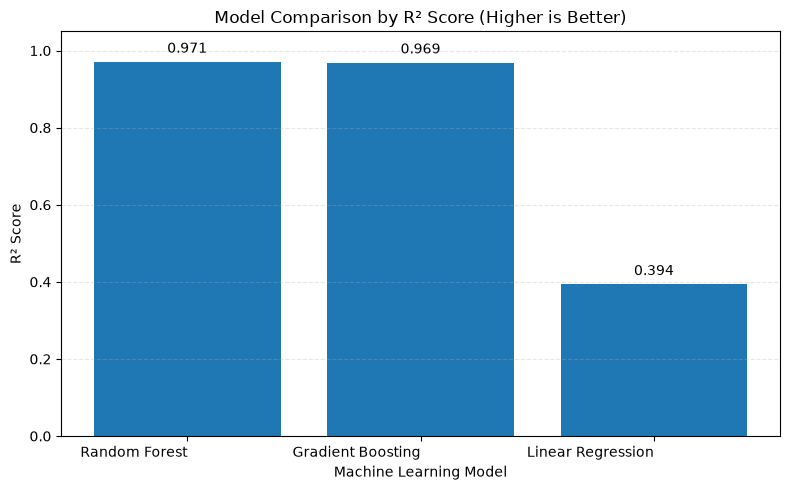

In [23]:
# R² Model Comparison Graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Model"],
    results_df["R2"],
)

plt.title("Model Comparison by R² Score (Higher is Better)")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Show R² values above bars
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 10. Recommend similar songs

In [11]:
# Pick a song name from the track column and run recommend_songs("song name").
rec_df = df.reset_index(drop=True).copy()
rec_X = rec_df[audio_cols].replace([np.inf, -np.inf], np.nan)
rec_X = rec_X.fillna(rec_X.median()).fillna(0)
rec_X = StandardScaler().fit_transform(rec_X)
neighbors = NearestNeighbors(metric="cosine").fit(rec_X)

def recommend_songs(song_name, count=5):
    matches = rec_df.index[rec_df["track"].astype(str).str.lower() == song_name.lower()].tolist()
    if not matches:
        print("Song not found. Check spelling in the track column.")
        return
    idx = matches[0]
    distances, indices = neighbors.kneighbors([rec_X[idx]], n_neighbors=min(count + 1, len(rec_df)))
    result = rec_df.iloc[indices[0][1:]][["artist", "track"]].copy()
    display(result.reset_index(drop=True))

# Example: recommend_songs("Blinding Lights")

## 11. Top 10 songs by custom popularity score

In [12]:
show_cols = [c for c in ["artist", "track", "popularity_score", "stream"] if c in df.columns]
display(df.sort_values("popularity_score", ascending=False)[show_cols].head(10))

,artist,track,popularity_score,stream
5113,Daddy Yankee,Despacito,96.46,1.506598e+09
16018,Luis Fonsi,Despacito,96.46,1.506598e+09
13781,BTS,Dynamite,96.02,1.582446e+09
102,Ed Sheeran,Shape of You,94.89,3.362005e+09
15967,Wiz Khalifa,See You Again (feat. Charlie Puth),94.67,1.521255e+09
13289,Charlie Puth,See You Again (feat. Charlie Puth),94.67,1.521255e+09
17597,Halsey,Boy With Luv (feat. Halsey),93.40,9.894780e+08
11177,BTS,Boy With Luv (feat. Halsey),93.40,9.894780e+08
14909,BTS,Butter,92.93,1.066002e+09
7572,Alan Walker,Faded,92.79,1.683178e+09


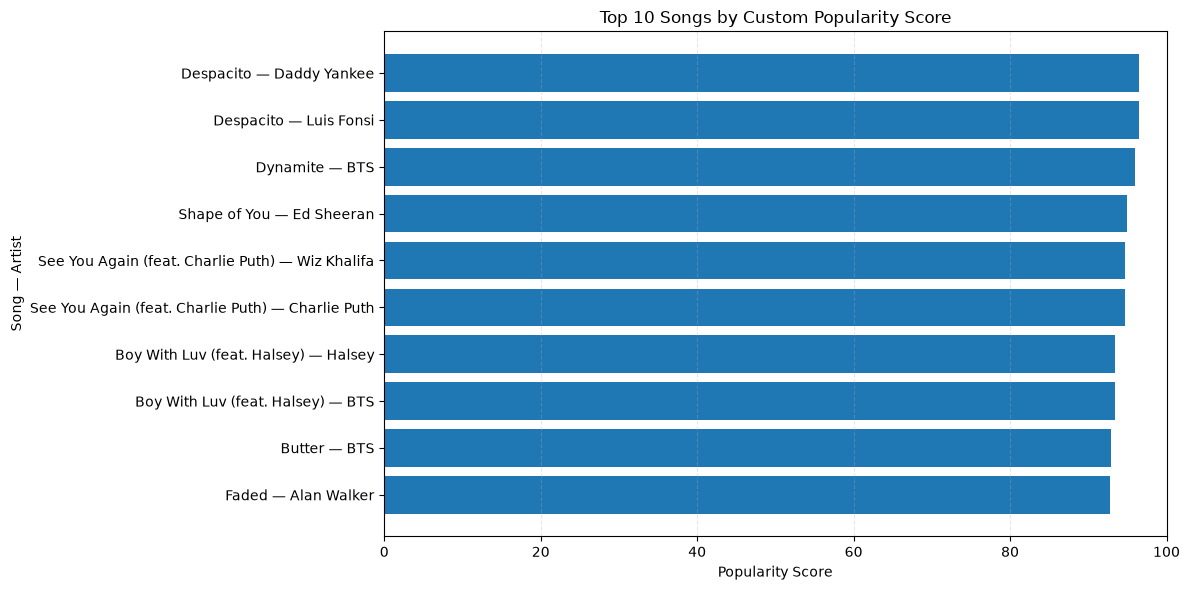

In [19]:
import matplotlib.pyplot as plt

# Get top 10 songs
top10 = df.sort_values(
    "popularity_score", ascending=False
).head(10).copy()

# Combine artist and track names
top10["song_label"] = top10["track"] + " — " + top10["artist"]

# Horizontal bar chart
plt.figure(figsize=(12, 6))
plt.barh(top10["song_label"][::-1], top10["popularity_score"][::-1])

plt.xlabel("Popularity Score")
plt.ylabel("Song — Artist")
plt.title("Top 10 Songs by Custom Popularity Score")
plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Close Cassandra connection

In [13]:
cluster.shutdown()
print("Cassandra connection closed")

Cassandra connection closed


## Notes
- Artist ranking uses **sum of `stream`** across an artist's songs.
- The top 5 songs for each top artist are ranked by summed streams.
- `popularity_score` is a custom 0–100 score, not Spotify's official score.
- The score is saved in the **same Cassandra table** (`spotify.spotify_youtube_full`).
- ML predicts this custom score from audio features; its accuracy depends on the dataset.
- The notebook reads data from Cassandra, not from the CSV.
- Cassandra must be running, and `row_id` must be the table's primary key.
